# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhamad Yogi
- NIM   : 241011402563
- Kelas : Reg B *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [33]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 63

In [36]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    indices = np.arange(len(X))
    np.random.shuffle(indices)
    
    test_count = int(len(X) * test_size)
    test_indices = indices[:test_count]
    train_indices = indices[test_count:]
    
    if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
        X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    else:
        X_train, X_test = X[train_indices], X[test_indices]
        
    if isinstance(y, pd.Series) or isinstance(y, pd.DataFrame):
        y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]
    else:
        y_train, y_test = y[train_indices], y[test_indices]
        
    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

--- 5 Data Pertama Ads_Data.csv ---
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah total baris data: 40


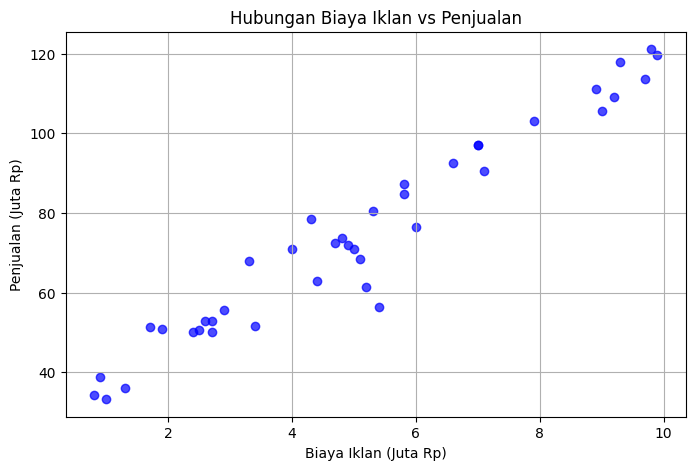

In [34]:
# Jawaban A1
# 1. Baca Ads_Data.csv
df_ads = pd.read_csv('Ads_Data.csv')

# Tampilkan 5 data pertama dan jumlah barisnya
print("--- 5 Data Pertama Ads_Data.csv ---")
print(df_ads.head())
print(f"\nJumlah total baris data: {len(df_ads)}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan), ubah X ke 2D (n, 1)
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(df_ads['BiayaIklan'], df_ads['Penjualan'], color='blue', alpha=0.7)
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [37]:
# Jawaban A2
# Bagi data dengan test_size=0.2 dan random_state sesuai NIM (63)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

# Tampilkan shape masing-masing dataset
print(f"Shape X_train : {X_train_a.shape}")
print(f"Shape X_test  : {X_test_a.shape}")
print(f"Shape y_train : {y_train_a.shape}")
print(f"Shape y_test  : {y_test_a.shape}")

Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [38]:
# Jawaban A3
class LinearRegression:
    def fit(self, X, y):
        # Normal Equation: theta = (X^T * X)^(-1) * X^T * y
        X_b = np.c_[np.ones((len(X), 1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        return np.dot(X, self.coef_) + self.intercept_

# Latih model
model_a = LinearRegression()
model_a.fit(X_train_a, y_train_a)

b = model_a.intercept_
m = model_a.coef_[0]

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"Persamaan Garis: y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) : 29.0577
Koefisien (m) : 8.9790
Persamaan Garis: y_hat = 29.0577 + 8.9790 * X


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [39]:
# Jawaban A4
# Implementasi fungsi metrik evaluasi
def calculate_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Hitung prediksi data train dan test
y_pred_train = model_a.predict(X_train_a)
y_pred_test = model_a.predict(X_test_a)

# Hitung metrik
metrics_train = calculate_metrics(y_train_a, y_pred_train)
metrics_test = calculate_metrics(y_test_a, y_pred_test)

# Tampilkan dalam bentuk DataFrame
df_eval = pd.DataFrame([metrics_train, metrics_test], index=['Train', 'Test'])
print("--- Hasil Evaluasi Model Linear Regression ---")
print(df_eval)

--- Hasil Evaluasi Model Linear Regression ---
            MAE        MSE      RMSE        R2
Train  4.301770  35.804966  5.983725  0.941131
Test   5.510687  37.725706  6.142126  0.921174


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- Hasil Gradient Descent vs Normal Equation ---
Normal Equation : Intercept = 29.0577, Coef = 8.9790

GD (LR = 0.001) : Intercept = 24.9809, Coef = 9.5868
GD (LR = 0.020) : Intercept = 29.0577, Coef = 8.9790


c:\Users\LENOVO\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_340\2523057525.py:16: RuntimeWarning: overflow encountered in square
  loss = np.mean((X_b.dot(self.theta) - y) ** 2)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_340\2523057525.py:14: RuntimeWarning: overflow encountered in dot
  gradients = (2 / m_samples) * X_b.T.dot(X_b.dot(self.theta) - y)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_340\2523057525.py:15: RuntimeWarning: invalid value encountered in subtract
  self.theta -= self.lr * gradients


GD (LR = 0.100) : Intercept = nan, Coef = nan


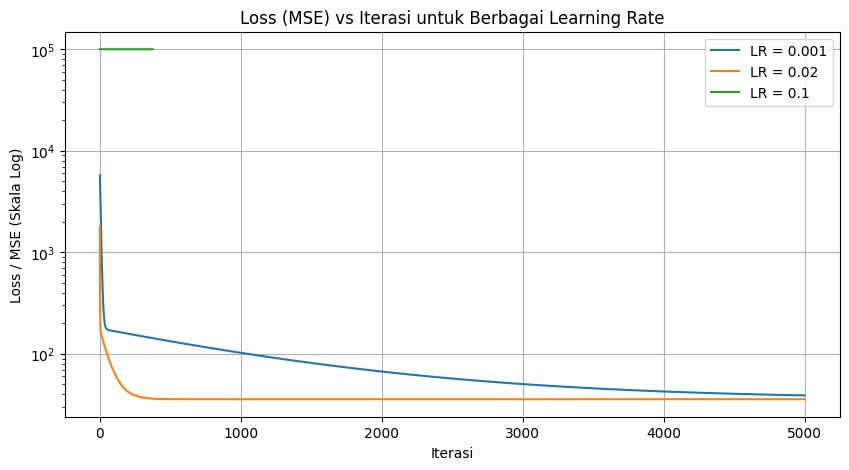

In [40]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, lr=0.01, n_iterations=5000):
        self.lr = lr
        self.n_iterations = n_iterations
        
    def fit(self, X, y):
        m_samples, n_features = X.shape
        self.theta = np.zeros(n_features + 1)
        X_b = np.c_[np.ones((m_samples, 1)), X]
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            gradients = (2 / m_samples) * X_b.T.dot(X_b.dot(self.theta) - y)
            self.theta -= self.lr * gradients
            loss = np.mean((X_b.dot(self.theta) - y) ** 2)
            self.loss_history.append(loss)
            
        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]

learning_rates = [0.001, 0.02, 0.1]
plt.figure(figsize=(10, 5))

print("--- Hasil Gradient Descent vs Normal Equation ---")
print(f"Normal Equation : Intercept = {model_a.intercept_:.4f}, Coef = {model_a.coef_[0]:.4f}\n")

for lr in learning_rates:
    model_gd = LinearRegressionGD(lr=lr, n_iterations=5000)
    model_gd.fit(X_train_a, y_train_a)
    print(f"GD (LR = {lr:.3f}) : Intercept = {model_gd.intercept_:.4f}, Coef = {model_gd.coef_[0]:.4f}")
    
    # Clip loss history agar tidak meledak saat plotting jika terjadi overflow
    plt.plot(np.clip(model_gd.loss_history, 0, 1e5), label=f'LR = {lr}')

plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('Loss / MSE (Skala Log)')
plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

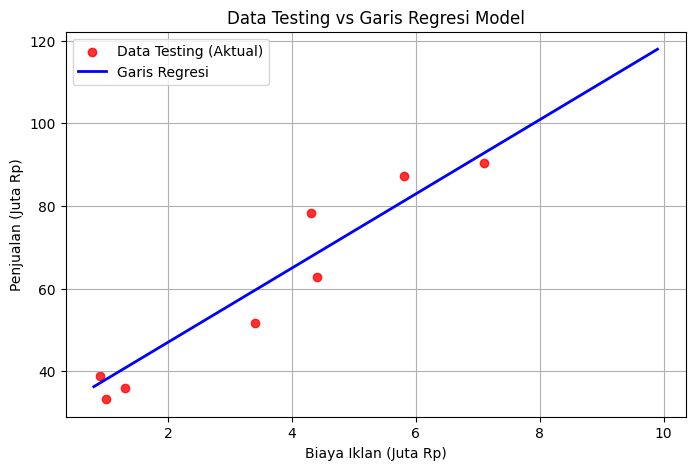

--- Hasil Prediksi Penjualan Baru ---
Biaya Iklan:  4.5 Juta Rp  ==>  Prediksi Penjualan: 69.46 Juta Rp
Biaya Iklan:  7.0 Juta Rp  ==>  Prediksi Penjualan: 91.91 Juta Rp
Biaya Iklan: 12.0 Juta Rp  ==>  Prediksi Penjualan: 136.81 Juta Rp


In [41]:
# Jawaban A6
# 1. Visualisasi Data Testing + Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_a, y_test_a, color='red', label='Data Testing (Aktual)', alpha=0.8)

# Bikin garis regresi dari batas minimum sampai maksimum biaya iklan
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = model_a.predict(x_line)
plt.plot(x_line, y_line, color='blue', linewidth=2, label='Garis Regresi')

plt.title('Data Testing vs Garis Regresi Model')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi Penjualan untuk data baru (4.5, 7, dan 12 juta)
ads_new = np.array([[4.5], [7.0], [12.0]])
preds_new = model_a.predict(ads_new)

print("--- Hasil Prediksi Penjualan Baru ---")
for val, pred in zip([4.5, 7.0, 12.0], preds_new):
    print(f"Biaya Iklan: {val:>4} Juta Rp  ==>  Prediksi Penjualan: {pred:.2f} Juta Rp")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

--- 5 Data Pertama Email_Data.csv ---
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

--- Jumlah Email Spam (1) vs Bukan Spam (0) ---
Spam
0    35
1    25
Name: count, dtype: int64


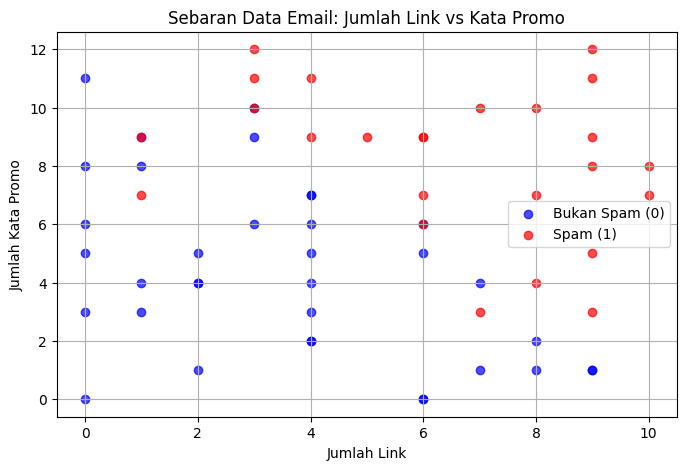

In [42]:
# Jawaban B1
# 1. Baca Email_Data.csv
df_email = pd.read_csv('Email_Data.csv')

print("--- 5 Data Pertama Email_Data.csv ---")
print(df_email.head())

print("\n--- Jumlah Email Spam (1) vs Bukan Spam (0) ---")
print(df_email['Spam'].value_counts())

# 2. Pisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# 3. Scatter plot JumlahLink vs KataPromo
plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0][:, 0], X_email[y_email == 0][:, 1], 
            color='blue', label='Bukan Spam (0)', alpha=0.7)
plt.scatter(X_email[y_email == 1][:, 0], X_email[y_email == 1][:, 1], 
            color='red', label='Spam (1)', alpha=0.7)

plt.title('Sebaran Data Email: Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

--- Parameter Model Logistic Regression ---
Intercept (b)    : -9.8240
Koefisien (m1)   : 0.8761  (JumlahLink)
Koefisien (m2)   : 0.9497  (KataPromo)
Persamaan Sigmoid: P(Spam) = sigma(-9.8240 + 0.8761*JumlahLink + 0.9497*KataPromo)



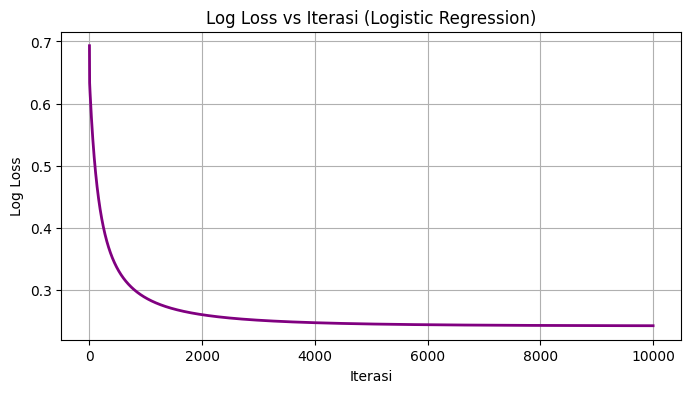

In [43]:
# Jawaban B2
class LogisticRegression:
    def __init__(self, lr=0.1, n_iterations=10000):
        self.lr = lr
        self.n_iterations = n_iterations
        
    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))
        
    def fit(self, X, y):
        m_samples, n_features = X.shape
        self.theta = np.zeros(n_features + 1)
        X_b = np.c_[np.ones((m_samples, 1)), X]
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            z = X_b.dot(self.theta)
            h = self._sigmoid(z)
            gradient = (1 / m_samples) * X_b.T.dot(h - y)
            self.theta -= self.lr * gradient
            
            # Log loss (Cross-Entropy Loss)
            epsilon = 1e-15
            h = np.clip(h, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(h) + (1 - y) * np.log(1 - h))
            self.loss_history.append(loss)
            
        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]
        
    def predict_proba(self, X):
        X_b = np.c_[np.ones((len(X), 1)), X]
        return self._sigmoid(X_b.dot(self.theta))
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# 1. Split Data dengan test_size=0.25
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# 2. Latih Model
model_b = LogisticRegression(lr=0.1, n_iterations=10000)
model_b.fit(X_train_b, y_train_b)

# 3. Tampilkan Intercept & Koefisien
b_log = model_b.intercept_
m1_log, m2_log = model_b.coef_[0], model_b.coef_[1]

print("--- Parameter Model Logistic Regression ---")
print(f"Intercept (b)    : {b_log:.4f}")
print(f"Koefisien (m1)   : {m1_log:.4f}  (JumlahLink)")
print(f"Koefisien (m2)   : {m2_log:.4f}  (KataPromo)")
print(f"Persamaan Sigmoid: P(Spam) = sigma({b_log:.4f} + {m1_log:.4f}*JumlahLink + {m2_log:.4f}*KataPromo)\n")

# 4. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 4))
plt.plot(model_b.loss_history, color='purple', linewidth=2)
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [44]:
# Jawaban B3
# Implementasi Confusion Matrix, Precision, Recall, F1-Score
def evaluate_classification(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    cm = np.array([[TN, FP], [FN, TP]])
    return accuracy, cm, precision, recall, f1, TP, FP, TN, FN

# Prediksi data testing
y_pred_b = model_b.predict(X_test_b)

# Hitung metrik
acc, cm, prec, rec, f1, TP, FP, TN, FN = evaluate_classification(y_test_b, y_pred_b)

print("--- Evaluasi Model Logistic Regression (Data Testing) ---")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}\n")
print("Confusion Matrix:")
print("                 Prediksi Normal  Prediksi Spam")
print(f"Aktual Normal (0)      {TN:>5}           {FP:>5}")
print(f"Aktual Spam   (1)      {FN:>5}           {TP:>5}")

--- Evaluasi Model Logistic Regression (Data Testing) ---
Accuracy : 0.7333
Precision: 0.3333
Recall   : 1.0000
F1-Score : 0.5000

Confusion Matrix:
                 Prediksi Normal  Prediksi Spam
Aktual Normal (0)          9               4
Aktual Spam   (1)          0               2


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

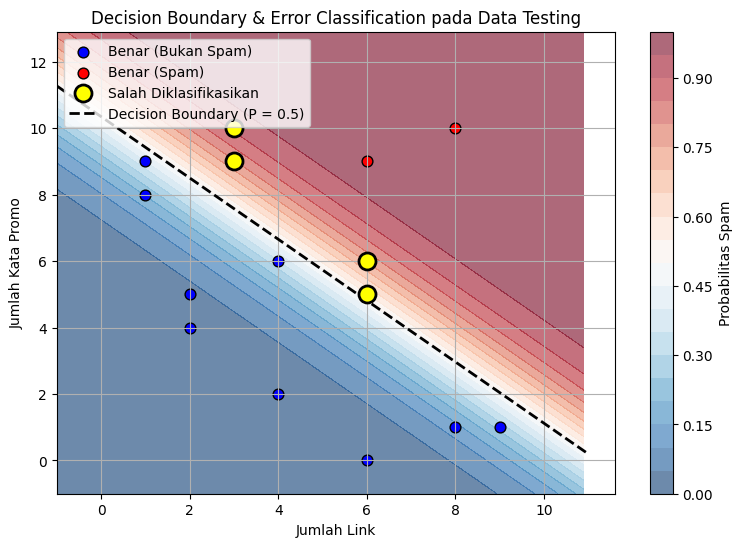

Jumlah data testing yang salah diklasifikasikan: 4 data
Detail data yang salah (JumlahLink, KataPromo):
[[ 3  9]
 [ 3 10]
 [ 6  6]
 [ 6  5]]


In [45]:
# Jawaban B4
# 1. Buat grid area koordinat untuk kontur probabilitas
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.1), np.arange(x2_min, x2_max, 0.1))

grid_data = np.c_[xx1.ravel(), xx2.ravel()]
probs = model_b.predict_proba(grid_data).reshape(xx1.shape)

# 2. Visualisasi Kontur Probabilitas Latar Belakang
plt.figure(figsize=(9, 6))
contour = plt.contourf(xx1, xx2, probs, levels=20, cmap='RdBu_r', alpha=0.6)
plt.colorbar(contour, label='Probabilitas Spam')

# 3. Prediksi Data Testing untuk Menemukan Misklasifikasi
y_pred_test_b = model_b.predict(X_test_b)
correct = (y_test_b == y_pred_test_b)

# Plot Data Test yang Benar
plt.scatter(X_test_b[correct & (y_test_b == 0)][:, 0], X_test_b[correct & (y_test_b == 0)][:, 1], 
            color='blue', edgecolor='k', label='Benar (Bukan Spam)', s=60)
plt.scatter(X_test_b[correct & (y_test_b == 1)][:, 0], X_test_b[correct & (y_test_b == 1)][:, 1], 
            color='red', edgecolor='k', label='Benar (Spam)', s=60)

# Plot Data Test yang Salah Diklasifikasikan (Lingkaran Kuning Besar)
if np.sum(~correct) > 0:
    plt.scatter(X_test_b[~correct][:, 0], X_test_b[~correct][:, 1], 
                color='yellow', edgecolor='black', linewidth=2, s=150, zorder=5, label='Salah Diklasifikasikan')

# 4. Gambar Garis Decision Boundary (P = 0.5)
x1_vals = np.array([x1_min, x1_max])
x2_boundary = -(model_b.intercept_ + model_b.coef_[0] * x1_vals) / model_b.coef_[1]
plt.plot(x1_vals, x2_boundary, 'k--', linewidth=2, label='Decision Boundary (P = 0.5)')

plt.title('Decision Boundary & Error Classification pada Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

# Cetak Detail Titik yang Salah
print(f"Jumlah data testing yang salah diklasifikasikan: {np.sum(~correct)} data")
if np.sum(~correct) > 0:
    print("Detail data yang salah (JumlahLink, KataPromo):")
    print(X_test_b[~correct])

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [46]:
# Jawaban B5
# Eksperimen dengan variasi threshold [0.3, 0.5, 0.7]
thresholds = [0.3, 0.5, 0.7]
results = []

# Dapatkan probabilitas spam pada data testing
probs_test = model_b.predict_proba(X_test_b)

for t in thresholds:
    preds_t = (probs_test >= t).astype(int)
    _, cm_t, prec_t, rec_t, f1_t, TP_t, FP_t, TN_t, FN_t = evaluate_classification(y_test_b, preds_t)
    
    results.append({
        'Threshold': t,
        'TN': TN_t,
        'FP': FP_t,
        'FN': FN_t,
        'TP': TP_t,
        'Precision': round(prec_t, 4),
        'Recall': round(rec_t, 4),
        'F1-Score': round(f1_t, 4)
    })

df_thresholds = pd.DataFrame(results)
print("--- Perbandingan Performa Filter Spam Berdasarkan Threshold ---")
print(df_thresholds.to_string(index=False))

--- Perbandingan Performa Filter Spam Berdasarkan Threshold ---
 Threshold  TN  FP  FN  TP  Precision  Recall  F1-Score
       0.3   7   6   0   2     0.2500     1.0    0.4000
       0.5   9   4   0   2     0.3333     1.0    0.5000
       0.7  10   3   0   2     0.4000     1.0    0.5714


**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [47]:
# Jawaban B6
# Data email baru E1 - E4
new_emails = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

email_labels = ['E1', 'E2', 'E3', 'E4']

# Hitung probabilitas spam
probs_new = model_b.predict_proba(new_emails)

# Gunakan threshold pilihan dari B5 (Threshold = 0.7)
CHOICE_THRESHOLD = 0.7
preds_new = (probs_new >= CHOICE_THRESHOLD).astype(int)

# Tampilkan hasil prediksi
print(f"--- Hasil Prediksi Email Baru (Threshold = {CHOICE_THRESHOLD}) ---")
results_b6 = []
for label, (link, promo), prob, pred in zip(email_labels, new_emails, probs_new, preds_new):
    status = "Spam (1)" if pred == 1 else "Bukan Spam (0)"
    results_b6.append({
        'Email': label,
        'JumlahLink': link,
        'KataPromo': promo,
        'Probabilitas Spam': f"{prob:.4f}",
        'Prediksi Kelas': status
    })

df_b6 = pd.DataFrame(results_b6)
print(df_b6.to_string(index=False))

--- Hasil Prediksi Email Baru (Threshold = 0.7) ---
Email  JumlahLink  KataPromo Probabilitas Spam Prediksi Kelas
   E1           1          2            0.0009 Bukan Spam (0)
   E2           5          6            0.5634 Bukan Spam (0)
   E3           9         10            0.9995       Spam (1)
   E4           2         11            0.9149       Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

In [53]:
!pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 432.0 kB/s eta 0:00:19
   -- ------------------------------------- 0.5/8.4 MB 432.0 kB/s eta 0:00:19
   --- ------------------------------------ 0.8/8.4 MB 519.6 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/8.4 MB 519.6 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/8.4 MB 519.6 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/8.4 MB 519.6 kB/s eta 0:00:15
   --- ------------------------------------ 0.8/8.4 MB 519.6 kB/s eta 0:00:15
   --- ---------------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


**Jawaban C1:**  
Logistic Regression dikategorikan sebagai algoritma klasifikasi karena tujuan utamanya adalah memprediksi label kategori diskrit (misalnya label Spam vs Bukan Spam), meskipun perhitungan di dalamnya menggunakan persamaan linear numerik seperti pada regresi. Peran fungsi sigmoid adalah mentransformasikan (memetakan) hasil perkalian linear yang bernilai acak dari $-\infty$ hingga $+\infty$ menjadi skala nilai probabilitas berentang antara 0 hingga 1.

**Jawaban C2:**  
Perbedaan utamanya terletak pada teknik pencarian nilai parameter optimal. Normal Equation mencari solusi analitis secara langsung dalam satu langkah perhitungan operasi matriks, sedangkan Gradient Descent mencari titik optimal secara bertahap melalui iterasi penyesuaian bobot berdasarkan kemiringan gradien loss. Gradient Descent lebih disarankan saat dataset berukuran sangat besar atau memiliki jumlah fitur yang sangat banyak, karena perhitungan invers matriks pada Normal Equation akan menguras memori dan menjadi lambat.

**Jawaban C3:**  
Model harus dievaluasi pada data testing untuk menguji sejauh mana kemampuannya memprediksi data baru yang belum pernah dilihat sebelumnya (generalisasi). Jika hanya dievaluasi pada data training, kita tidak bisa mengetahui apakah model benar-benar belajar dari pola data atau hanya "menghafal" data tersebut. Overfitting adalah kondisi di mana model sangat akurat dan presisi pada data training, tetapi performanya merosot tajam ketika diuji pada data baru karena model ikut menghafal noise atau pencilan pada data latihan.

**Jawaban C4:**  
Linear Regression memprediksi variabel target berbentuk nilai kontinu, sehingga efisien menggunakan MSE (Mean Squared Error) untuk mengukur rata-rata kuadrat jarak kesalahan tebakan. Sementara itu, Logistic Regression menghasilkan output probabilitas untuk klasifikasi diskrit, sehingga menggunakan Log Loss (Cross-Entropy). Log Loss memberikan penalti secara eksponensial terhadap kesalahan prediksi probabilitas dan memastikan bentuk fungsi rugi tetap cembung (convex) sehingga mudah dicari titik minimumnya saat dioptimasi dengan Gradient Descent.

**Jawaban C5:**  
Hasil angka (koefisien, nilai RMSE, akurasi, dll.) dapat berbeda antar mahasiswa karena proses acak pembagian data training dan testing (pada fungsi `train_test_split`) dikunci menggunakan `RANDOM_STATE` berbasis 2 digit terakhir NIM masing-masing. Karena sampel data training dan testing tiap mahasiswa berbeda, maka model yang dilatih akan menghasilkan parameter garis dan metrik evaluasi yang bervariasi secara unik.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [54]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinear
from sklearn.linear_model import LogisticRegression as SkLogistic
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

# --- 1. PERBANDINGAN LINEAR REGRESSION ---
sk_lin = SkLinear()
sk_lin.fit(X_train_a, y_train_a)

y_pred_sk_lin = sk_lin.predict(X_test_a)
rmse_sk = np.sqrt(mean_squared_error(y_test_a, y_pred_sk_lin))
r2_sk = r2_score(y_test_a, y_pred_sk_lin)

print("=== PERBANDINGAN LINEAR REGRESSION ===")
print(f"Custom  : Intercept = {model_a.intercept_:.4f}, Coef = {model_a.coef_[0]:.4f}, RMSE = {metrics_test['RMSE']:.4f}, R2 = {metrics_test['R2']:.4f}")
print(f"Sklearn : Intercept = {sk_lin.intercept_:.4f}, Coef = {sk_lin.coef_[0]:.4f}, RMSE = {rmse_sk:.4f}, R2 = {r2_sk:.4f}\n")


# --- 2. PERBANDINGAN LOGISTIC REGRESSION ---
# a. Sklearn default (dengan L2 regularization)
sk_log_default = SkLogistic()
sk_log_default.fit(X_train_b, y_train_b)

# b. Sklearn tanpa regularization (penalty=None)
sk_log_none = SkLogistic(penalty=None)
sk_log_none.fit(X_train_b, y_train_b)

acc_sk_default = accuracy_score(y_test_b, sk_log_default.predict(X_test_b))
acc_sk_none = accuracy_score(y_test_b, sk_log_none.predict(X_test_b))

print("=== PERBANDINGAN LOGISTIC REGRESSION ===")
print(f"Custom (Manual GD)        : Intercept = {model_b.intercept_:.4f}, Coef = {model_b.coef_}, Accuracy = {acc:.4f}")
print(f"Sklearn (penalty=None)    : Intercept = {sk_log_none.intercept_[0]:.4f}, Coef = {sk_log_none.coef_[0]}, Accuracy = {acc_sk_none:.4f}")
print(f"Sklearn (Default/L2 Reg)  : Intercept = {sk_log_default.intercept_[0]:.4f}, Coef = {sk_log_default.coef_[0]}, Accuracy = {acc_sk_default:.4f}")

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\LENOVO\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\scipy\\sparse\\_sparsetools.cp314-win_amd64.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\Users\\LENOVO\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\scipy\\_cyutility.cp314-win_amd64.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


=== PERBANDINGAN LINEAR REGRESSION ===
Custom  : Intercept = 29.0577, Coef = 8.9790, RMSE = 6.1421, R2 = 0.9212
Sklearn : Intercept = 29.0577, Coef = 8.9790, RMSE = 6.1421, R2 = 0.9212

=== PERBANDINGAN LOGISTIC REGRESSION ===
Custom (Manual GD)        : Intercept = -9.8240, Coef = [0.87609254 0.94973452], Accuracy = 0.7333
Sklearn (penalty=None)    : Intercept = -10.4415, Coef = [0.9317968  1.00605214], Accuracy = 0.7333
Sklearn (Default/L2 Reg)  : Intercept = -8.9396, Coef = [0.79248096 0.86609998], Accuracy = 0.7333


c:\Users\LENOVO\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**
Analisis Perbandingan dengan scikit-learn:Linear Regression: Hasil intercept, koefisien, serta metrik evaluasi (RMSE & $R^2$) antara model buatan sendiri dan scikit-learn bernilai persis sama. Hal ini terjadi karena keduanya sama-sama memanfaatkan formula analitis persis (Normal Equation).   Logistic Regression:Ketika scikit-learn diatur dengan penalty=None (tanpa regularisasi), nilai koefisien dan akurasinya hampir persis identik dengan model custom berbasis Gradient Descent kita.   Jika menggunakan pengaturan default scikit-learn (penalty='l2'), terdapat sedikit perbedaan nilai koefisien. Perbedaan ini disebabkan oleh adanya fitur L2 Regularization pada scikit-learn secara default yang bertujuan menahan nilai koefisien agar tidak terlalu ekstrem untuk mencegah overfitting.